# 04 · Quanto cobrar? (regressão)

**Pergunta de negócio:** *qual o preço justo por m² (ou metro linear) para um novo orçamento, e o que faz o preço
variar?*

Hoje o preço sai da **tabela oficial**, ajustado "de cabeça" conforme a obra e o cliente. Isso gera dois problemas
concretos nos dados:
- **117 orçamentos "a combinar"**, enviados sem preço. O cliente fica esperando, e o notebook 03 mostrou que
  demora derruba o fechamento.
- **Gesso 3D e Boiserie não têm preço na tabela oficial**, então cada orçamento desses é calculado do zero.

## Por que regressão?

O alvo é um **valor numérico contínuo** (R$ por unidade), e há histórico de preços praticados para aprender.
É um problema **supervisionado de regressão**.

**Alvo:** `preco_cheio`, o preço unitário **antes do desconto** concedido. O desconto é uma decisão comercial
separada (analisada no notebook 03). Aqui interessa o preço "de lista" que a obra justifica.

## Algoritmos comparados

| Algoritmo | Por que testar |
|---|---|
| Baseline: preço de tabela | É o que a empresa faz hoje. O modelo só vale a pena se errar menos que ela |
| **Regressão Linear** | Simples e interpretável; com o alvo em log, cada coeficiente vira um efeito em % |
| **Gradient Boosting** (`HistGradientBoostingRegressor`) | Captura efeitos não lineares (ex.: o desconto por volume tem um teto) e interações |

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo_graficos as eg

eg.aplicar_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
DIR_PROC = RAIZ / "dados" / "processed"

import shap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from preparar_dados import ler_processados

## 1. Preparação

| Variável | Tipo | Por quê |
|---|---|---|
| `item` | categórica | Tipo + subtipo do serviço (ex.: "Gesso Liso · Parede de Tijolo"). É o principal determinante do preço |
| `log_quantidade` | numérica | Tamanho da obra; obras maiores costumam ter desconto por volume |
| `cidade` | categórica | Deslocamento e poder de compra variam por cidade |
| `tipo_imovel` | categórica | Residencial, comercial ou industrial |
| `segmento` | categórica | Segmento do cliente (notebook 02) |

**Excluídas para não vazar a resposta:** `valor_unitario_aplicado`, `valor_total` e `desconto_pct`, que são
calculados *a partir* do preço. O preço de tabela também fica de fora como variável, porque o `item` já carrega
essa informação.

**Alvo em log.** Os preços vão de ~R$ 12 (moldura) a ~R$ 200 (gesso 3D). Prever o log do preço faz o modelo
pensar em **porcentagens** ("Poços de Caldas cobra +12%"), que é como os ajustes de preço funcionam na prática.
Sem o log, os itens caros dominariam o erro.

In [2]:
dados = ler_processados()
segmentos = pd.read_csv(DIR_PROC / "segmentos.csv")
orc = dados["orcamentos"].merge(segmentos, on="id_cliente", how="left")
orc["subtipo"] = orc["subtipo"].fillna("")
orc["item"] = orc["tipo_servico"] + np.where(orc["subtipo"] != "", " · " + orc["subtipo"], "")
orc["log_quantidade"] = np.log(orc["quantidade"])

NUMERICAS = ["log_quantidade"]
CATEGORICAS = ["item", "cidade", "tipo_imovel", "segmento"]
VARIAVEIS = NUMERICAS + CATEGORICAS

com_preco = orc[orc["preco_cheio"].notna() & orc["quantidade"].notna()].copy()
a_combinar = orc[(orc["preco_a_combinar"] == 1) & orc["quantidade"].notna()].copy()
print(f"Orçamentos com preço (treino/teste): {len(com_preco)}")
print(f"Orçamentos 'a combinar' (para estimar): {len(a_combinar)}")
print(f"Itens diferentes: {com_preco['item'].nunique()}")

Orçamentos com preço (treino/teste): 1464
Orçamentos 'a combinar' (para estimar): 115
Itens diferentes: 12


**Divisão treino × teste: aleatória (80/20).** Diferente do notebook 03, aqui não há "futuro" a prever: o objetivo é
precificar qualquer orçamento a partir dos preços praticados, e a tabela não mudou no período. A divisão é
estratificada por item, para que todos os serviços apareçam nas duas partes.

In [3]:
treino, teste = train_test_split(com_preco, test_size=0.2, random_state=42, stratify=com_preco["item"])
X_treino, y_treino = treino[VARIAVEIS], np.log(treino["preco_cheio"])
X_teste, y_teste = teste[VARIAVEIS], teste["preco_cheio"]
print(f"Treino: {len(treino)}  |  Teste: {len(teste)}")

Treino: 1171  |  Teste: 293


## 2. Treino e avaliação

**Métricas (calculadas em R$, no preço real):**
- **MAE:** erro médio absoluto, em R$ por m² ou por metro linear.
- **MAPE:** erro médio percentual. É a métrica mais justa aqui, porque errar R$ 5 em uma moldura de R$ 15 é muito pior que em um forro de R$ 95.
- **R²:** fração da variação de preços explicada. Atenção: ele fica alto até para o baseline, porque o tipo de
  serviço sozinho já explica muito. Por isso não é a métrica principal.

In [4]:
# Na Linear, uma categoria de referência sai de cada variável: os coeficientes passam a ser lidos
# como "em relação a" (ex.: cidade em relação a São João da Boa Vista)
REFERENCIAS = {"item": "Forro Drywall", "cidade": "São João da Boa Vista",
               "tipo_imovel": "residencial", "segmento": "Residencial econômico"}

def preprocessador(com_referencia=False):
    drop = [REFERENCIAS[c] for c in CATEGORICAS] if com_referencia else None
    return ColumnTransformer([
        ("num", "passthrough", NUMERICAS),
        ("cat", OneHotEncoder(drop=drop, handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ], verbose_feature_names_out=False)

modelos = {
    "Regressão Linear": Pipeline([("prep", preprocessador(com_referencia=True)), ("modelo", LinearRegression())]),
    "Gradient Boosting": Pipeline([("prep", preprocessador()), ("modelo", HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, max_depth=4, min_samples_leaf=15, random_state=42))]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
for nome, pipe in modelos.items():
    erro = -cross_val_score(pipe, X_treino, y_treino, cv=cv, scoring="neg_mean_absolute_error")
    print(f"{nome:<18} validação cruzada: erro médio em log = {erro.mean():.4f} (±{erro.std():.4f})"
          f"  ≈ {np.expm1(erro.mean()):.1%} de erro típico")

Regressão Linear   validação cruzada: erro médio em log = 0.0421 (±0.0027)  ≈ 4.3% de erro típico


Gradient Boosting  validação cruzada: erro médio em log = 0.0446 (±0.0025)  ≈ 4.6% de erro típico


In [5]:
# Baseline: preço da tabela oficial. Para Gesso 3D e Boiserie (sem tabela), a mediana praticada NO TREINO.
mediana_treino = treino.groupby("tipo_servico")["preco_cheio"].median()
baseline = np.where(teste["tabela_oficial"] == 1, teste["valor_tabela"],
                    teste["tipo_servico"].map(mediana_treino))

previsoes = {"Baseline (tabela)": baseline}
for nome, pipe in modelos.items():
    pipe.fit(X_treino, y_treino)
    previsoes[nome] = np.exp(pipe.predict(X_teste))

resultados = pd.DataFrame({
    nome: {
        "MAE (R$)": mean_absolute_error(y_teste, p),
        "RMSE (R$)": root_mean_squared_error(y_teste, p),
        "MAPE": mean_absolute_percentage_error(y_teste, p),
        "R²": r2_score(y_teste, p),
    } for nome, p in previsoes.items()
}).T
resultados.assign(MAPE=resultados["MAPE"].map("{:.1%}".format)).round(3)

,MAE (R$),RMSE (R$),MAPE,R²
Baseline (tabela),9.01,12.84,11.7%,0.92
Regressão Linear,3.08,4.51,4.0%,0.99
Gradient Boosting,3.31,5.19,4.3%,0.99


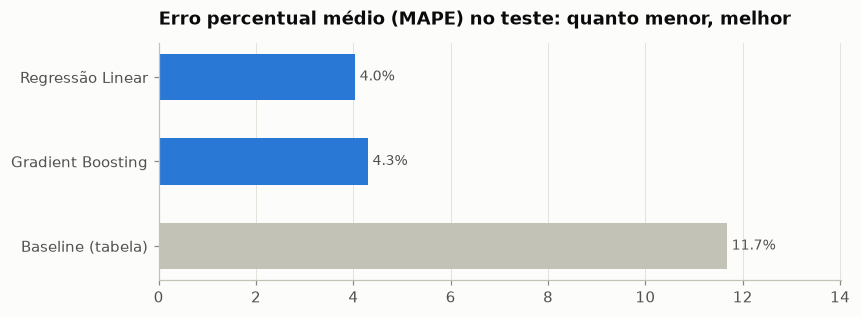

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.8))
mape = resultados["MAPE"].sort_values(ascending=False)
cores = [eg.NEUTRO if n.startswith("Baseline") else eg.CORES[0] for n in mape.index]
barras = ax.barh(mape.index, mape.values * 100, color=cores, height=0.55)
eg.rotular_barras(ax, barras, "{:.1f}%")
ax.set_xlim(0, mape.max() * 100 * 1.2)
ax.set_title("Erro percentual médio (MAPE) no teste: quanto menor, melhor")
ax.grid(axis="y", visible=False)
plt.show()

**Escolha: Regressão Linear.**
- Os dois modelos reduzem o erro da tabela para cerca de **um terço**: o MAPE cai de 11,7% para **4,0%** (Linear)
  e 4,3% (Gradient Boosting), e o MAE cai de R$ 9,01 para **R$ 3,08** por unidade.
- A Linear é um pouco melhor e **muito mais simples**: cada coeficiente é um ajuste percentual que cabe numa
  planilha. Como no notebook 03, vale a parcimônia. O Gradient Boosting fica como conferência (seção 3b).
- Parte do erro restante (~4%) é a variação de negociação caso a caso, que nenhuma variável disponível explica.

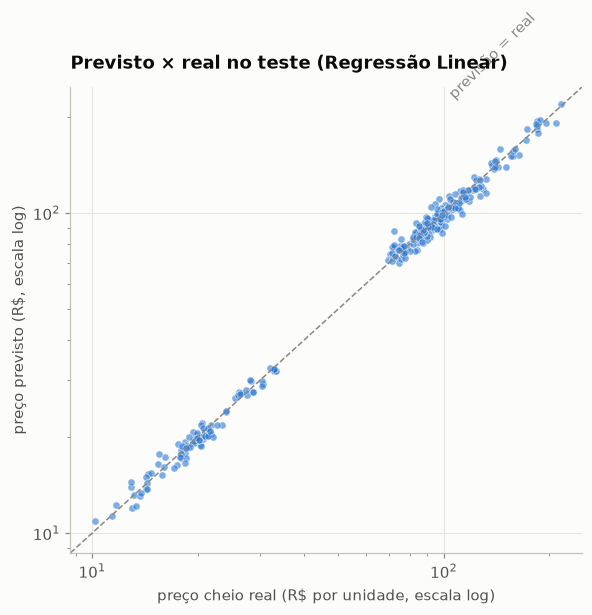

In [7]:
prev = previsoes["Regressão Linear"]

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(y_teste, prev, s=22, color=eg.CORES[0], alpha=0.6, edgecolor=eg.FUNDO, linewidth=0.5)
limites = [y_teste.min() * 0.85, y_teste.max() * 1.15]
ax.plot(limites, limites, color=eg.TINTA_SUAVE, linestyle="--", linewidth=1)
ax.text(limites[1] * 0.75, limites[1] * 0.92, "previsão = real", color=eg.TINTA_SUAVE, ha="right", rotation=45)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_xlabel("preço cheio real (R$ por unidade, escala log)")
ax.set_ylabel("preço previsto (R$, escala log)")
ax.set_title("Previsto × real no teste (Regressão Linear)")
plt.show()

## 3. Interpretação: o que faz o preço variar?

### a) Coeficientes da Regressão Linear

Com o alvo em log, cada coeficiente vira diretamente um **efeito percentual no preço**, mantendo todo o resto
igual. Para as categóricas, a comparação é com a categoria de referência (cidade = São João da Boa Vista,
segmento = Residencial econômico, imóvel = residencial).

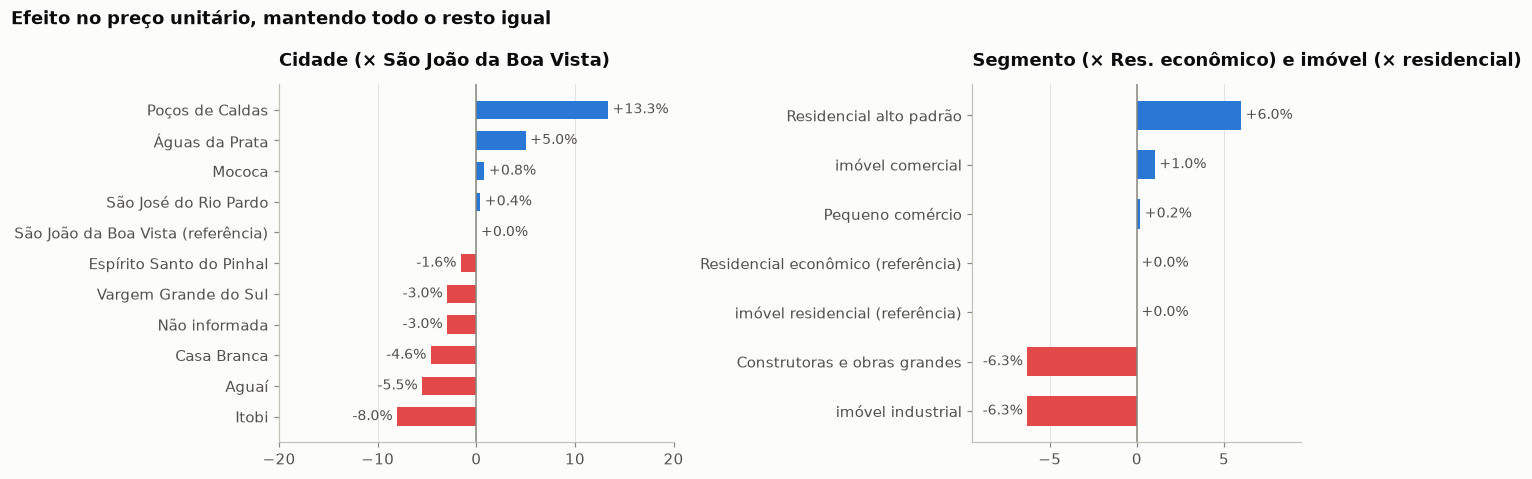

Quantidade: dobrar o tamanho da obra muda o preço unitário em -1.9%


In [8]:
modelo = modelos["Regressão Linear"]
coef = pd.Series(modelo.named_steps["modelo"].coef_, index=modelo.named_steps["prep"].get_feature_names_out())
efeito_pct = np.expm1(coef) * 100

def efeitos_de(variavel):
    e = efeito_pct[efeito_pct.index.str.startswith(variavel + "_")]
    e.index = e.index.str.removeprefix(variavel + "_")
    return pd.concat([e, pd.Series({REFERENCIAS[variavel] + " (referência)": 0.0})]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
segmento_imovel = pd.concat([efeitos_de("segmento"),
                             efeitos_de("tipo_imovel").rename(lambda i: "imóvel " + i)]).sort_values()
for ax, efeito, titulo in [(axes[0], efeitos_de("cidade"), "Cidade (× São João da Boa Vista)"),
                           (axes[1], segmento_imovel, "Segmento (× Res. econômico) e imóvel (× residencial)")]:
    cores = [eg.CORES[0] if v > 0 else (eg.NEUTRO if v == 0 else eg.CORES[7]) for v in efeito.values]
    barras = ax.barh(efeito.index, efeito.values, color=cores, height=0.6)
    eg.rotular_barras(ax, barras, "{:+.1f}%")
    ax.axvline(0, color=eg.TINTA_SUAVE, linewidth=1)
    margem = max(abs(efeito.min()), abs(efeito.max())) * 1.5
    ax.set_xlim(-margem, margem)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
fig.suptitle("Efeito no preço unitário, mantendo todo o resto igual", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

dobro = np.expm1(np.log(2) * coef["log_quantidade"]) * 100
print(f"Quantidade: dobrar o tamanho da obra muda o preço unitário em {dobro:+.1f}%")

### b) Conferência com SHAP: o desconto por volume é constante?

A Linear supõe que dobrar a quantidade **sempre** reduz o preço na mesma proporção. O Gradient Boosting não faz
essa suposição. O **SHAP** mostra, orçamento a orçamento, quanto a quantidade "empurrou" o preço previsto
para cima ou para baixo. Como o alvo está em log, cada contribuição é uma porcentagem do preço.

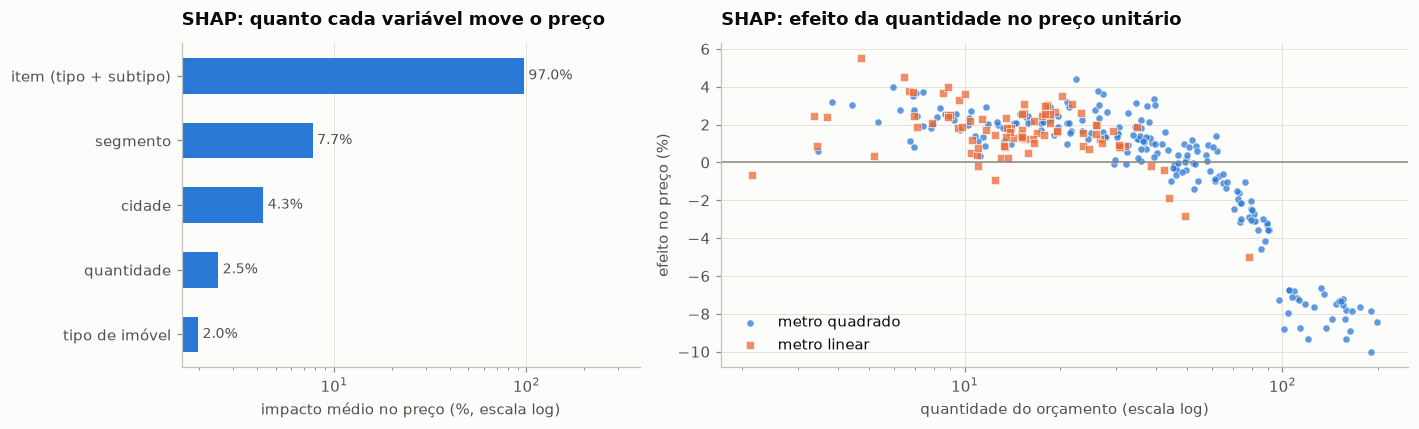

In [9]:
gb = modelos["Gradient Boosting"]
X_teste_t = pd.DataFrame(gb.named_steps["prep"].transform(X_teste),
                         columns=gb.named_steps["prep"].get_feature_names_out(), index=X_teste.index)
valores_shap = shap.TreeExplainer(gb.named_steps["modelo"]).shap_values(X_teste_t)
shap_df = pd.DataFrame(valores_shap, columns=X_teste_t.columns, index=X_teste.index)

# as colunas do one-hot (cidade_Mococa, cidade_Itobi...) são somadas de volta na variável original
def variavel_original(coluna):
    return next((v for v in CATEGORICAS if coluna.startswith(v + "_")), coluna)

shap_por_variavel = shap_df.T.groupby(variavel_original).sum().T
importancia = shap_por_variavel.abs().mean().sort_values()
rotulos = {"item": "item (tipo + subtipo)", "log_quantidade": "quantidade", "cidade": "cidade",
           "segmento": "segmento", "tipo_imovel": "tipo de imóvel"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.5]})
barras = axes[0].barh([rotulos[i] for i in importancia.index], np.expm1(importancia.values) * 100,
                      color=eg.CORES[0], height=0.55)
eg.rotular_barras(axes[0], barras, "{:.1f}%")
axes[0].set_xscale("log")
axes[0].set_xlim(right=importancia.pipe(np.expm1).max() * 100 * 4)
axes[0].set_xlabel("impacto médio no preço (%, escala log)")
axes[0].set_title("SHAP: quanto cada variável move o preço")
axes[0].grid(axis="y", visible=False)

for i, unidade in enumerate(["metro quadrado", "metro linear"]):
    m = teste["unidade_medida"] == unidade
    axes[1].scatter(teste.loc[m, "quantidade"], np.expm1(shap_por_variavel.loc[m, "log_quantidade"]) * 100,
                    s=22, color=eg.CORES[i], marker=eg.MARCADORES[i], alpha=0.75, edgecolor=eg.FUNDO,
                    linewidth=0.5, label=unidade)
axes[1].axhline(0, color=eg.TINTA_SUAVE, linewidth=1)
axes[1].set_xscale("log")
axes[1].set_xlabel("quantidade do orçamento (escala log)")
axes[1].set_ylabel("efeito no preço (%)")
axes[1].set_title("SHAP: efeito da quantidade no preço unitário")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Leitura:**
- **Depois do tipo de serviço, a cidade é o maior ajuste de preço.** Poços de Caldas paga **+13%** em relação a
  São João da Boa Vista, e Águas da Prata, +5%. Itobi (−8%), Aguaí (−5,5%) e Casa Branca (−4,6%) pagam menos.
  São cerca de 21 pontos percentuais entre a cidade mais cara e a mais barata, para o mesmo serviço.
- **Construtoras pagam ~6% menos** (negociação de quem compra muito), e **imóvel industrial também ~6% menos**
  (acabamento mais simples). O **residencial alto padrão paga ~6% mais**, e o notebook 03 mostrou que isso não
  reduz o fechamento.
- **O pequeno comércio paga o mesmo que o residencial econômico** (+0,2%). Ou seja, o segmento que menos fecha
  não está pagando mais caro: a causa da baixa conversão não é preço acima do mercado.
- **Volume:** na Linear, dobrar o tamanho da obra reduz o preço unitário em ~2%. O SHAP do Gradient Boosting
  mostra que o efeito **não é constante**: até ~40 m² o preço é praticamente cheio, e acima de 100 m² o desconto
  chega a 7–10%. A Linear acerta na média, mas **subestima o desconto em obras muito grandes**. Nesses casos, convém
  conferir o preço sugerido.

## 4. Aplicação

### a) Preço sugerido para os orçamentos "a combinar"

O modelo final é retreinado com **todos** os orçamentos com preço e aplicado aos que foram enviados sem preço:

In [10]:
final = Pipeline([("prep", preprocessador(com_referencia=True)), ("modelo", LinearRegression())])
final.fit(com_preco[VARIAVEIS], np.log(com_preco["preco_cheio"]))

a_combinar["preco_sugerido"] = np.exp(final.predict(a_combinar[VARIAVEIS])).round(2)
a_combinar["valor_estimado"] = (a_combinar["preco_sugerido"] * a_combinar["quantidade"]).round(2)
a_combinar["preco_tabela"] = a_combinar["valor_tabela"]

tabela = a_combinar.sort_values("valor_estimado", ascending=False)[
    ["id_servico", "item", "cidade", "segmento", "quantidade", "unidade_medida",
     "preco_tabela", "preco_sugerido", "valor_estimado", "situacao"]].set_index("id_servico")
tabela.head(12)

,item,cidade,segmento,quantidade,unidade_medida,preco_tabela,preco_sugerido,valor_estimado,situacao
id_servico,,,,,,,,,
847,Divisória Drywall,Não informada,Construtoras e obras grandes,214.14,metro quadrado,130.00,107.71,"23,065.02",fechado
83,Divisória Drywall,Aguaí,Construtoras e obras grandes,169.54,metro quadrado,130.00,97.93,"16,603.05",fechado
132,Divisória Drywall,Aguaí,Construtoras e obras grandes,151.05,metro quadrado,130.00,105.85,"15,988.64",perdido
767,Divisória Drywall,São José do Rio Pardo,Construtoras e obras grandes,116.56,metro quadrado,130.00,113.27,"13,202.75",fechado
621,Divisória Drywall,Espírito Santo do Pinhal,Construtoras e obras grandes,117.93,metro quadrado,130.00,110.78,"13,064.29",fechado
1373,Forro Drywall,Aguaí,Construtoras e obras grandes,170.64,metro quadrado,95.00,71.57,"12,212.70",perdido
475,Divisória Drywall,Mococa,Construtoras e obras grandes,114.70,metro quadrado,130.00,105.20,"12,066.44",perdido
710,Gesso 3D,São José do Rio Pardo,Residencial alto padrão,62.94,metro quadrado,187.37,188.26,"11,849.08",perdido
1201,Forro Drywall,Poços de Caldas,Construtoras e obras grandes,126.37,metro quadrado,95.00,93.15,"11,771.37",fechado


In [11]:
resumo_combinar = a_combinar.groupby("situacao")["valor_estimado"].agg(["size", "sum"])
resumo_combinar.columns = ["orçamentos", "valor estimado (R$)"]
resumo_combinar

,orçamentos,valor estimado (R$)
situacao,,
fechado,69,"238,536.80"
pendente,1,"10,196.22"
perdido,45,"172,995.28"


### b) Preço oficial sugerido para Gesso 3D e Boiserie

Situação padrão: obra residencial em São João da Boa Vista, cliente residencial alto padrão (quem mais compra
esses itens) e quantidade típica:

In [12]:
sugestoes = []
for item in ["Gesso 3D", "Boiserie"]:
    qtd_tipica = com_preco.loc[com_preco["item"] == item, "quantidade"].median()
    caso = pd.DataFrame([{"item": item, "log_quantidade": np.log(qtd_tipica), "cidade": "São João da Boa Vista",
                          "tipo_imovel": "residencial", "segmento": "Residencial alto padrão"}])
    praticado = com_preco.loc[com_preco["item"] == item, "preco_cheio"]
    sugestoes.append({
        "item": item,
        "unidade": com_preco.loc[com_preco["item"] == item, "unidade_medida"].iloc[0],
        "quantidade típica": round(qtd_tipica, 1),
        "preço sugerido (R$)": round(float(np.exp(final.predict(caso))[0]), 2),
        "praticado: mín (R$)": praticado.min(),
        "praticado: mediana (R$)": praticado.median(),
        "praticado: máx (R$)": praticado.max(),
    })
sugestoes = pd.DataFrame(sugestoes).set_index("item")
sugestoes

,unidade,quantidade típica,preço sugerido (R$),praticado: mín (R$),praticado: mediana (R$),praticado: máx (R$)
item,,,,,,
Gesso 3D,metro quadrado,27.50,191.60,167.99,187.37,215.24
Boiserie,metro linear,19.20,157.86,136.06,155.56,185.80


In [13]:
metricas = {
    "modelo_escolhido": "Regressão Linear",
    "teste": {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in resultados.T.to_dict().items()},
    "efeito_cidade": efeitos_de("cidade").round(1).to_dict(),
    "efeito_segmento": efeitos_de("segmento").round(1).to_dict(),
    "efeito_imovel": efeitos_de("tipo_imovel").round(1).to_dict(),
    "efeito_dobrar_quantidade": round(float(dobro), 1),
    "a_combinar": {"orcamentos": int(len(a_combinar)),
                   "valor_estimado_total": round(float(a_combinar["valor_estimado"].sum()), 2),
                   "por_situacao": resumo_combinar.round(2).to_dict("index")},
    "sugestao_tabela": sugestoes["preço sugerido (R$)"].to_dict(),
}
_ = (DIR_PROC / "metricas_regressao.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2))

## Insights e recomendações

1. **Preço calculado em minutos, com ~4% de erro.** Trocar a tabela única por "tabela + ajustes" (cidade, segmento,
   tipo de imóvel e volume) reduz o erro de preço de 11,7% para 4,0%. Os coeficientes cabem numa planilha simples.
   Isso acaba com o orçamento "a combinar" e acelera o envio, que o notebook 03 mostrou ser decisivo (−18% de
   chance de fechar por dia de atraso).
2. **Oficializar o preço por cidade.** Hoje a tabela é a mesma para toda a região, mas na prática Poços de Caldas
   já paga +13% e Itobi/Aguaí/Casa Branca de 5% a 8% menos. Colocar isso na tabela evita sub-cobrar onde o mercado aceita mais.
3. **Incluir Gesso 3D e Boiserie na tabela oficial**, com preço sugerido de **R$ 191,60/m²** e **R$ 157,86/metro
   linear** (situação padrão), coerentes com as medianas praticadas (R$ 187 e R$ 156).
4. **Registrar o preço sempre.** 69 serviços **fechados** ficaram sem preço registrado. O modelo estima **~R$ 239
   mil** de faturamento nesses serviços, que hoje não aparece em nenhum controle da empresa.
5. **Política de desconto por volume por escrito:** sem desconto até ~40 m², chegando a ~10% acima de 100 m². Isso formaliza
   o que já acontece e, junto com o teto de 10–12% de desconto comercial do notebook 03, evita descontos no improviso.